# Estimer par Monte-Carlo l’incertitude sur les paramètres d’un modèle
### Mesurer l’indice de réfraction du plexiglas

**Capacité numérique — PCSI et PSI.** Simuler la variation de mesures expérimentales et répéter un ajustement pour estimer l’incertitude sur ses paramètres.

**À savoir faire.** Justifier la ligne qui refait l’ajustement à chaque tirage, puis lire l’incertitude-type sur la pente et sur l’indice.

Pour afficher les commandes, sélectionner **Run → Run All Cells**.

## Des angles à l’indice

Pour un rayon passant de l’air au plexiglas, la loi de Snell-Descartes donne $\sin i=n_{\mathrm{plexi}}\sin r$, avec l’indice de l’air pris égal à 1. On choisit $x=\sin i$, $y=\sin r$ et on ajuste $y=ax+b$. On en déduit **$n_{\mathrm{plexi}}=1/a$**. L’ordonnée à l’origine $b$ devrait être proche de zéro dans ce modèle.

| Variable | Signification |
|---|---|
| <code>i_mes</code>, <code>r_mes</code> | Angles mesurés d’incidence et de réfraction, en degrés. |
| <code>di</code>, <code>dr</code> | Demi-largeurs des intervalles de lecture, en degrés. |
| <code>N</code> | Nombre de jeux de mesures simulés, donc d’ajustements. |
| <code>a</code>, <code>b</code> | Pente et ordonnée à l’origine de la droite ajustée. Les deux sont sans unité. |

On suppose ici que, dans chaque intervalle de lecture, toutes les valeurs sont également plausibles. D’où le tirage **uniforme entre les deux bornes**. Par exemple, un angle lu à $30°$ avec une demi-largeur de $0{,}5°$ est simulé entre $29{,}5°$ et $30{,}5°$.

In [ ]:
import matplotlib.pyplot as plt
from IPython.display import display

try:
    import ipywidgets as widgets
except ModuleNotFoundError:
    import piplite
    await piplite.install("ipywidgets==8.1.8")
    import ipywidgets as widgets

## Mesures de réfraction

Les valeurs ci-dessous sont celles du TP d’origine. Le dernier point est écarté par défaut comme dans l’ajustement initial du TP. Il est possible de le réintégrer et d’observer son effet sur la droite.

In [ ]:
import numpy as np

i_mes = np.array([0, 5, 10, 15, 20, 25, 30, 35, 40, 45, 50, 55, 65, 70, 75, 80, 85])
r_mes = np.array([0, 3.5, 7, 10, 13.5, 17, 20, 23, 26, 29, 31, 33.5, 38, 40, 41, 43, 46])
di = np.full(i_mes.size, 0.5)
dr = np.array([0.5, 1, 1, 1, 1, 1, 1, 1.5, 1.5, 1.5, 1.5, 1.5, 1.5, 1.5, 2, 2.5, 4])

## Lire le calcul Monte-Carlo

| Code Python | Ce que fait la ligne |
|---|---|
| <code>i = np.random.uniform(i_mes - di, i_mes + di)</code> | Tirer une incidence par mesure, dans l’intervalle de lecture correspondant. |
| <code>r = np.random.uniform(r_mes - dr, r_mes + dr)</code> | Faire de même, indépendamment, pour la réfraction. Avec <code>di = 0</code>, seule la réfraction varie. |
| <code>x = np.sin(np.deg2rad(i))</code> et <code>y = np.sin(np.deg2rad(r))</code> | Passer des angles en degrés aux sinus utilisés dans le modèle. |
| <code>a, b = np.polyfit(x, y, 1)</code> | Ajuster une droite à **ce jeu de mesures simulé**. |
| <code>indices = 1 / pentes</code> | Calculer un indice par ajustement. L’écart-type des indices estime l’incertitude-type sur l’indice. |

Répéter les quatre premières étapes $N$ fois pour obtenir $N$ valeurs de $a$ et de $b$.

In [ ]:
def simuler_ajustements(i_mes, r_mes, di, dr, N):
    pentes, ordonnees = [], []
    for _ in range(N):
        i = np.random.uniform(i_mes - di, i_mes + di)
        r = np.random.uniform(r_mes - dr, r_mes + dr)
        x = np.sin(np.deg2rad(i))
        y = np.sin(np.deg2rad(r))
        a, b = np.polyfit(x, y, 1)
        pentes.append(a)
        ordonnees.append(b)
    return np.array(pentes), np.array(ordonnees)

## Manipuler

Commencer avec les incertitudes de lecture du TP. Réduire ensuite la demi-largeur des intervalles de réfraction en réglant son multiplicateur à **0,5**. Comparer l’histogramme et l’incertitude sur l’indice.

Le champ et le curseur permettent de régler le nombre de tirages. Le bouton **Simuler** renouvelle les tirages aux mêmes réglages. Tester ensuite, si souhaité, l’effet du dernier point.

In [ ]:
N = widgets.BoundedIntText(value=1000, min=10, max=5000, description="Tirages",
                           layout=widgets.Layout(width="155px"))
curseur = widgets.IntSlider(value=1000, min=10, max=5000, step=10,
                             continuous_update=False, readout=False, description="N")
liaison = widgets.link((N, "value"), (curseur, "value"))
precision = widgets.FloatSlider(value=1, min=0, max=2, step=0.1, continuous_update=False,
                                 description="Facteur sur dr",
                                 style={"description_width": "initial"})
incidence_variable = widgets.Checkbox(value=True, description="Faire aussi varier l’incidence")
dernier_point = widgets.Checkbox(value=False, description="Inclure le dernier point (85°)")
lancer = widgets.Button(description="Simuler", button_style="primary")
sortie = widgets.Output()

def afficher_simulation(_=None):
    points = slice(None) if dernier_point.value else slice(None, -1)
    i, r = i_mes[points], r_mes[points]
    demi_i = di[points] if incidence_variable.value else np.zeros_like(i, dtype=float)
    demi_r = dr[points] * precision.value
    x, y = np.sin(np.deg2rad(i)), np.sin(np.deg2rad(r))
    a_nominal, b_nominal = np.polyfit(x, y, 1)
    pentes, ordonnees = simuler_ajustements(i, r, demi_i, demi_r, N.value)
    indices = 1 / pentes

    with sortie:
        sortie.clear_output(wait=True)
        print(f"{N.value} ajustements · {len(i)} couples de mesures")
        print(f"Pente a : {np.mean(pentes):.4f} ± {np.std(pentes):.4f}")
        print(f"Ordonnée à l’origine b : {np.mean(ordonnees):.4f} ± {np.std(ordonnees):.4f}")
        print(f"Indice du plexiglas : {np.mean(indices):.4f} ± {np.std(indices):.4f}")
        print("Les valeurs après ± sont les incertitudes-types estimées.")

        fig, (gauche, droite) = plt.subplots(1, 2, figsize=(8.8, 3.5), layout="constrained")
        grille = np.linspace(0, 1, 100)
        gauche.scatter(x, y, s=17, color="#147889", label="Points retenus")
        if not dernier_point.value:
            gauche.scatter(np.sin(np.deg2rad(i_mes[-1])), np.sin(np.deg2rad(r_mes[-1])),
                            s=35, facecolors="none", edgecolors="#9f3b24", label="Point écarté")
        gauche.plot(grille, a_nominal * grille + b_nominal, color="#203a55", label="Droite nominale")
        gauche.set(xlabel="sin(i)", ylabel="sin(r)", title="Ajustement des mesures")
        gauche.legend(fontsize=8)
        droite.hist(indices, bins=30, color="#147889", edgecolor="white")
        droite.axvline(1 / a_nominal, color="#9f3b24", linestyle="--", label="Indice nominal")
        droite.set(xlabel="Indice du plexiglas", ylabel="Nombre de tirages", title="Indices simulés")
        droite.legend(fontsize=8)
        plt.show()
        plt.close(fig)

for commande in (N, precision, incidence_variable, dernier_point):
    commande.observe(afficher_simulation, names="value")
lancer.on_click(afficher_simulation)
display(widgets.VBox([
    widgets.Box([N, curseur], layout=widgets.Layout(display="flex", flex_flow="row wrap")),
    precision, incidence_variable, dernier_point, lancer, sortie,
]))
afficher_simulation()

## Compléter une ligne

Dans la boucle, les angles ont été tirés et convertis en sinus. Compléter la ligne d’ajustement qui donne la pente et l’ordonnée à l’origine.

```python
x = np.sin(np.deg2rad(i))
y = np.sin(np.deg2rad(r))
a, b = …
pentes.append(a)
ordonnees.append(b)
```

Le champ **Essai** sert de brouillon. La solution s’ouvre avec ou sans saisie.

In [ ]:
essai = widgets.Text(placeholder="Expression après a, b =", description="Essai",
                     layout=widgets.Layout(width="min(100%, 500px)"))
solution = widgets.HTML("<pre>a, b = np.polyfit(x, y, 1)</pre>"
                        "<p>Le degré 1 demande une droite. Refaire l’ajustement pour chaque jeu tiré.</p>")
corrige = widgets.Accordion(children=[solution], selected_index=None)
corrige.set_title(0, "Afficher la solution")
display(widgets.VBox([essai, corrige]))

## Interpréter

Pourquoi répéter l’ajustement ? Que représente l’écart-type des indices obtenus ? Réfléchir, puis ouvrir l’explication.

In [ ]:
texte = widgets.HTML("<p>Les angles simulés changent à chaque essai. La pente varie, "
                     "et l’indice 1/a varie avec elle. L’écart-type des indices simulés "
                     "estime l’incertitude-type due aux incertitudes de lecture modélisées.</p>")
reponse = widgets.Accordion(children=[texte], selected_index=None)
reponse.set_title(0, "Afficher l’explication")
display(reponse)

## À retenir — Des angles mesurés à l’indice

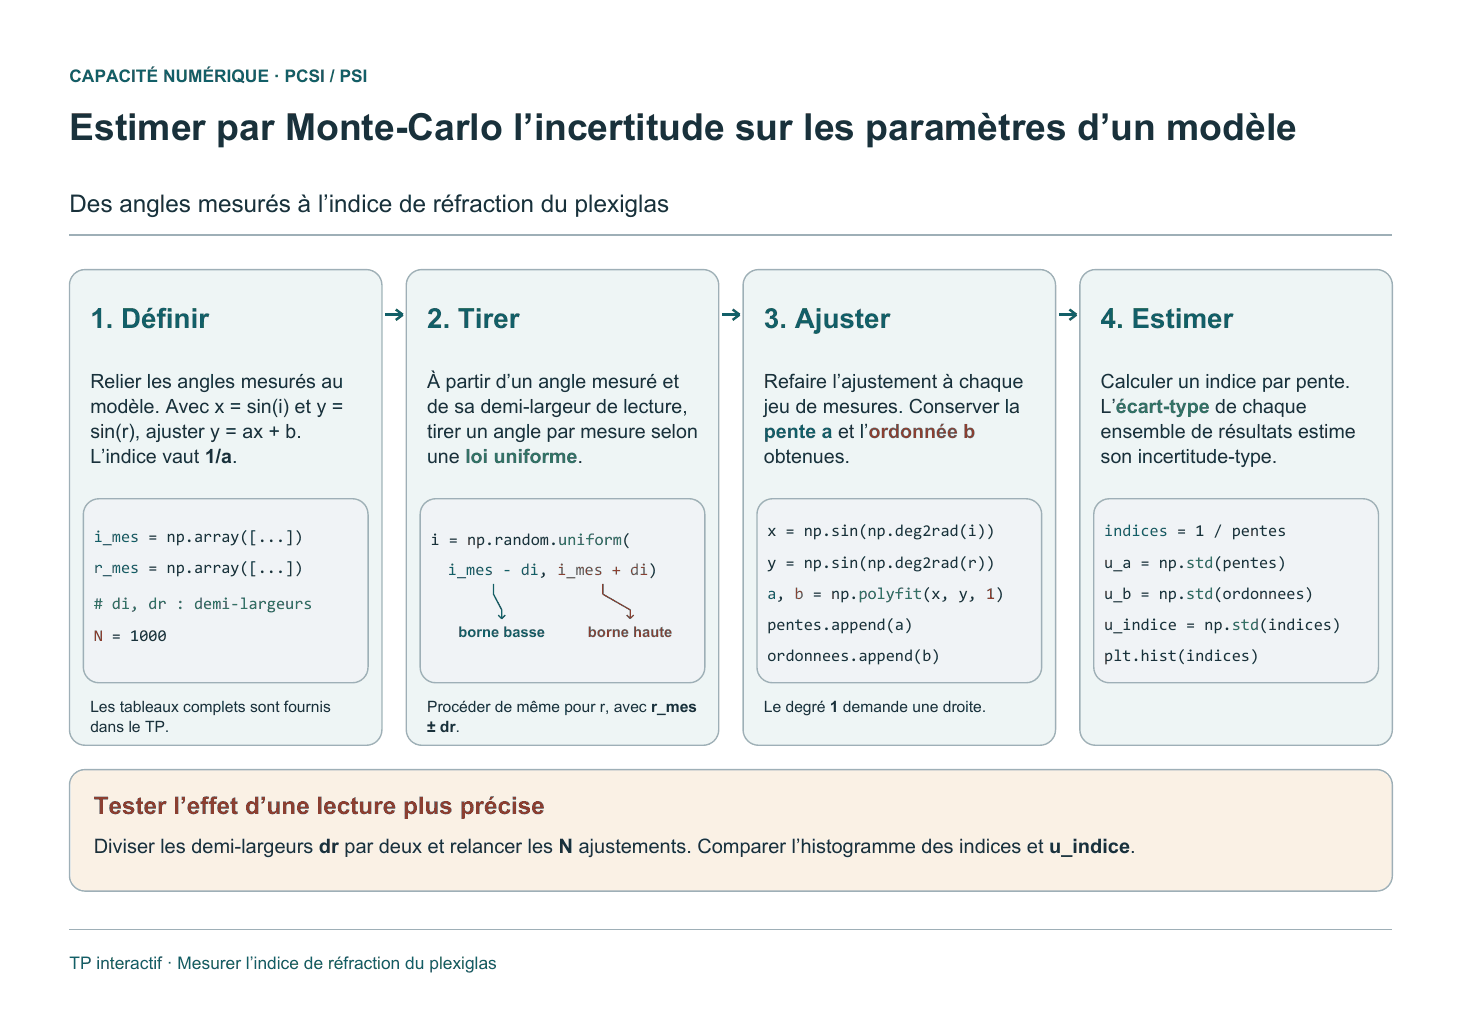

*Adapté des activités 3 et 3 bis de « Étude expérimentale de lois physiques ».*